# T09 — Choosing an engine and checking convergence

`groundfield` solves the same physical problem with several numerical
methods (*backends*). They differ in the soils they accept, in how they
represent the current on the wires, and in cost. This tutorial runs
one problem through every engine, explains the differences, and shows
how to check that a result has converged with respect to the
discretisation — against an exact reference.

**You will learn**

- which backends exist, what they can do, and which names are
  deprecated aliases;
- how to compare engines with `gf.compare_engines`;
- the difference between the exact line-source kernel (the default of
  the image family) and the point kernel;
- how to run and read a `gf.convergence_study`.

Runtime: a few seconds.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.references import dwight1936
from groundfield.solver.registry import get_backend

print("groundfield", gf.__version__)

groundfield 0.15.0


## The engine family

Backends are registered in a registry; each declares its
*capabilities*, and `Engine.solve` checks them before any work is
done.

In [2]:
print(f"{'backend':15s} {'soils':35s} {'kernels':15s} junctions  experimental")
for name in gf.available_backends():
    spec = get_backend(name)
    cap = spec.capabilities
    print(
        f"{name:15s} {', '.join(sorted(cap.soils)):35s} {', '.join(sorted(cap.kernels)) or '-':15s} "
        f"{str(cap.junctions):10s} {spec.experimental}"
    )
print(
    "deprecated aliases:",
    [
        n
        for n in gf.available_backends(include_deprecated=True)
        if n not in gf.available_backends()
    ],
)

backend         soils                               kernels         junctions  experimental
image           homogeneous                         line, point     True       False
image_2layer    two_layer                           line, point     True       False
mom             homogeneous, two_layer              point           True       False
mom_sommerfeld  homogeneous, multi_layer, two_layer point           True       False
fem             homogeneous, multi_layer, two_layer -               True       True
deprecated aliases: ['image_nlayer', 'cim', 'bem']


| Backend | Current on the wires | Green's function | Use it for |
|---|---|---|---|
| `image` (default) | one uniform leakage current per electrode (per layer for wires through an interface) | image method; exact line-source kernel | impedances, networks, parameter studies — fast; forwards a two-layer soil to `image_2layer` |
| `image_2layer` | as `image` | Tagg/Sunde image series | two-layer soil (selected automatically) |
| `mom` | piecewise constant on every segment, point matching at the segment midpoints | closed form (homogeneous) or Tagg/Sunde series (two layers) | field quantities next to extended electrodes (touch and step voltages near grids) |
| `mom_sommerfeld` | as `mom` | Sommerfeld integral by quadrature | any number of layers; reference for the soil model |
| `fem` (experimental) | follows from the field: the electrodes are solid bodies at one potential | axisymmetric finite elements | an independent reference for a rod, a ring or a ring with a central rod in any layered soil; refuses every other world |

The names `cim`, `bem` and `image_nlayer` still work but are deprecated
aliases: `cim` runs the image dispatch, `bem` runs `mom`, and
`image_nlayer` is the internal dispatch target of `image` for a
`MultiLayerSoil`. They warn and will be removed in 2027.5 at the
earliest.

## One problem, every engine

Two 2 m rods, 4 m apart, bonded by an ideal conductor, in 100 Ω·m;
1 A into one of them. `gf.compare_engines` solves the world with every
engine and tabulates impedances (real and imaginary part, every
frequency) against a tolerance.

In [3]:
def two_rods():
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=100.0))
    gf.create_electrode(
        world,
        "rod",
        name="rod_a",
        position=(0.0, 0.0, 0.5),
        length=2.0,
        wire_radius=0.01,
    )
    gf.create_electrode(
        world,
        "rod",
        name="rod_b",
        position=(4.0, 0.0, 0.5),
        length=2.0,
        wire_radius=0.01,
    )
    gf.create_conductor(world, name="bond", start="rod_a", end="rod_b")  # ideal bond
    gf.create_source(world, attached_to="rod_a", magnitude=1.0)
    return world


engines = {
    "image": gf.create_engine(backend="image", segment_length=0.25),
    "image, point kernel": gf.create_engine(
        backend="image", segment_length=0.25, kernel="point"
    ),
    "mom": gf.create_engine(backend="mom", segment_length=0.25),
    "mom_sommerfeld": gf.create_engine(backend="mom_sommerfeld", segment_length=0.25),
}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    comparison = gf.compare_engines(two_rods(), engines)
print(comparison.summary())
print()
for w in caught:
    print(f"{w.category.__name__}: {w.message}")

Cross-engine comparison, tolerance 5.0 %
Engines: image, image, point kernel, mom, mom_sommerfeld
Frequencies: 50 Hz

Quantity             f [Hz]  part           image  image, point kernel             mom  mom_sommerfeld   dev [%]  ok
Z_cluster[rod_a]          50  Re           23.0996         22.8595         22.7759         22.7759     1.421  yes
Z_cluster[rod_a]          50  Im                 0               0               0               0     0.000  yes
Z_in[source_0]            50  Re           23.0996         22.8595         22.7759         22.7759     1.421  yes
Z_in[source_0]            50  Im                 0               0               0               0     0.000  yes

Consistent.



In [4]:
z = {
    name: values[0].real
    for name, values in comparison.impedances["Z_in[source_0]"].items()
}
assert (
    abs(z["mom"] / z["mom_sommerfeld"] - 1.0) < 1e-9
)  # same discretisation, same soil
assert abs(z["image"] / z["mom"] - 1.0) < 0.03

How to read the table:

- `mom` and `mom_sommerfeld` agree to all digits: in homogeneous soil
  they assemble the same system. Their agreement checks the
  *Green's function* (in layered soil), not the discretisation.
- `image` and `mom` differ by a few percent. That is the difference
  between two current ansätze, not an error of either; for
  impedances both are acceptable, for fields next to extended
  electrodes `mom` is the better choice (tutorial
  [T08](T08_touch_and_step_assessment.ipynb)).
- The point kernel lies below the line kernel; the convergence study
  below shows which of the two is right.
- `fem` is not in the table: two rods side by side are not
  axisymmetric, and its conforming model refuses them with a message
  that names the backends which solve the world. For a single rod, a
  ring or a ring with a central rod it solves the electrodes as the
  solid bodies they are and is an independent reference.

A deprecated alias gives exactly the result of its target — and is
therefore no independent cross-check:

In [5]:
world = two_rods()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    z_cim = (
        gf.create_engine(backend="cim", segment_length=0.25)
        .solve(world)
        .input_impedance()[0]
        .real
    )
    z_bem = (
        gf.create_engine(backend="bem", segment_length=0.25)
        .solve(world)
        .input_impedance()[0]
        .real
    )
print(
    f"cim -> {z_cim:.6f} Ohm (image {z['image']:.6f}), bem -> {z_bem:.6f} Ohm (mom {z['mom']:.6f})"
)
for w in caught:
    print(f"{w.category.__name__}: {w.message}")

cim -> 23.099571 Ohm (image 23.099571), bem -> 22.775865 Ohm (mom 22.775865)


In [6]:
assert z_cim == z["image"] and abs(z_bem - z["mom"]) < 1e-12 * z_bem
assert all(issubclass(w.category, DeprecationWarning) for w in caught)

Capabilities are checked before the solve. Asking `mom` for the
line-source kernel, for example, fails at once and names the backends
that can do it:

In [7]:
try:
    gf.create_engine(backend="mom", kernel="line").solve(world)
except gf.BackendCapabilityError as exc:
    print("BackendCapabilityError:", exc)

BackendCapabilityError: Backend 'mom' cannot solve this world: it does not implement kernel 'line' (supported: 'point'). Backends that can: 'image', 'fem' (experimental).


## Convergence against an exact reference

For a straight rod of length $L$ and radius $a$ that starts at the
surface and leaks a *uniform* current, the average-potential method
(Howe; the method behind Dwight's formulas) gives the resistance as a
closed form. Averaging the potential of the line current and of its
image over the rod (reduced kernel $1/\sqrt{(z - z')^2 + a^2}$),

$$
R = \frac{\rho}{4\pi L^2}\,(D + I),\qquad
D = 2\Bigl[L\,\operatorname{arsinh}\frac{L}{a} - \sqrt{L^2 + a^2} + a\Bigr],
$$

$$
I = \sqrt{L^2 + a^2} - a + 2L\Bigl[\operatorname{arsinh}\frac{2L}{a}
    - \operatorname{arsinh}\frac{L}{a}\Bigr]
    - \Bigl[\sqrt{4L^2 + a^2} - \sqrt{L^2 + a^2}\Bigr].
$$

Dwight's $\frac{\rho}{2\pi L}(\ln\frac{4L}{a} - 1)$ is its limit for
$a \ll L$. This is the model of the image backend, so its result must
converge to $R$; we refine the segment length from 1 m to 6.25 cm with
`gf.convergence_study`, which clones the engine for every segment
length and tabulates the impedance.

In [8]:
RHO, L, A = 100.0, 3.0, 0.008


def rod():
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO))
    gf.create_electrode(
        world, "rod", name="rod", position=(0.0, 0.0, 0.0), length=L, wire_radius=A
    )
    gf.create_source(world, attached_to="rod", magnitude=1.0)
    return world


D = 2 * (L * np.arcsinh(L / A) - np.hypot(L, A) + A)
I = (
    np.hypot(L, A)
    - A
    + 2 * L * (np.arcsinh(2 * L / A) - np.arcsinh(L / A))
    - (np.hypot(2 * L, A) - np.hypot(L, A))
)
r_exact = RHO / (4 * np.pi * L**2) * (D + I)
print(
    f"exact uniform-current resistance: {r_exact:.6f} Ohm (Dwight: {dwight1936.rod(RHO, L, A):.6f} Ohm)"
)

ladder = [1.0, 0.5, 0.25, 0.125, 0.0625]
studies = {
    "image, line kernel (default)": gf.create_engine(),
    "image, point kernel": gf.create_engine(kernel="point"),
    "mom": gf.create_engine(backend="mom"),
}
convergence = {
    name: gf.convergence_study(rod(), eng, segment_lengths=ladder)
    for name, eng in studies.items()
}
for name, df in convergence.items():
    deviation = df["Z_re"].to_numpy() / r_exact - 1.0
    print(f"{name:30s}", "  ".join(f"{d:+.2e}" for d in deviation))

exact uniform-current resistance: 33.499746 Ohm (Dwight: 33.492674 Ohm)


image, line kernel (default)   +0.00e+00  -1.03e-06  -1.16e-06  +1.83e-06  +1.66e-05
image, point kernel            -5.74e-03  -1.21e-02  -1.53e-02  -1.69e-02  -1.77e-02
mom                            -7.45e-03  -1.53e-02  -2.00e-02  -2.29e-02  -2.48e-02


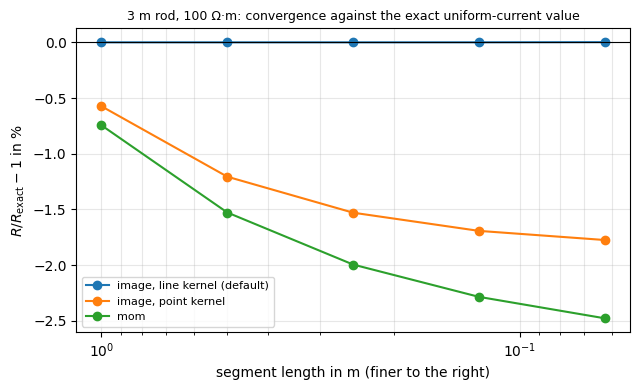

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for name, df in convergence.items():
    ax.semilogx(
        df["segment_length_m"], 100 * (df["Z_re"] / r_exact - 1.0), "o-", label=name
    )
ax.axhline(0.0, color="k", lw=0.8)
ax.invert_xaxis()
ax.set_xlabel("segment length in m (finer to the right)")
ax.set_ylabel(r"$R / R_\mathrm{exact} - 1$ in %")
ax.set_title(
    "3 m rod, 100 Ω·m: convergence against the exact uniform-current value", fontsize=9
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

In [10]:
line = convergence["image, line kernel (default)"]["Z_re"].to_numpy() / r_exact - 1.0
point = convergence["image, point kernel"]["Z_re"].to_numpy() / r_exact - 1.0
assert np.all(np.abs(line) < 2e-5)  # exact at every segment length
assert np.all(point < -0.005) and np.all(
    np.diff(point) < 0
)  # converges to a wrong value

The line kernel integrates the potential of each segment exactly, so
the uniform-current solution is reproduced at every segment length.
The point kernel puts each segment's current into its midpoint; its
error does not vanish under refinement — it converges to a value
1–2 % too low. The `mom` backend shares the point kernel and in
addition lets the current vary along the rod; it drifts with the
segment length and stays below as well. This is why the image family
uses the line kernel by default since this release (`kernel="point"`
reproduces the numbers of releases up to 0.15.0).

## Curved electrodes: chords converge with $\Delta s^2$

A ring is discretised into straight chords, so even the exact line
kernel sees a polygon. The polygon converges to the circle with the
square of the segment length: every halving of $\Delta s$ should cut
the change of the result by about four.

Z_ring (line kernel): [6.28644 6.31396 6.32208 6.32421 6.32471]
change per halving:   [0.02752 0.00812 0.00212 0.00051]
ratio of successive changes: [3.39 3.83 4.17]


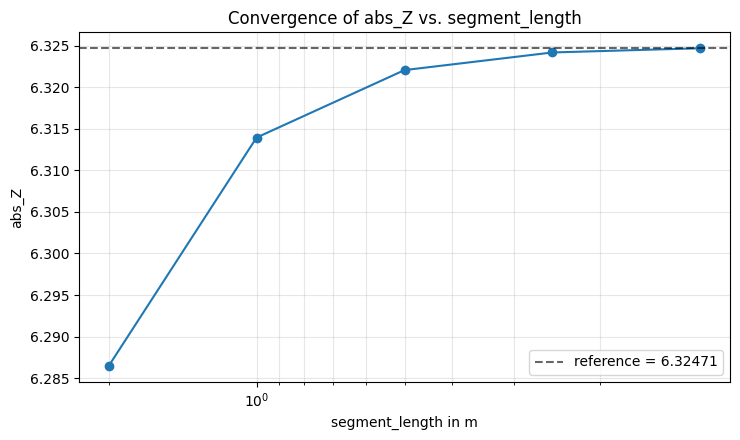

In [11]:
def ring():
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO))
    gf.create_electrode(
        world,
        "ring",
        name="ring",
        center=(0.0, 0.0, 0.6),
        radius=5.0,
        wire_radius=0.005,
    )
    gf.create_source(world, attached_to="ring", magnitude=1.0)
    return world


ring_ladder = [2.0, 1.0, 0.5, 0.25, 0.125]
ring_line = gf.convergence_study(
    ring(), gf.create_engine(), segment_lengths=ring_ladder
)["Z_re"].to_numpy()
steps = np.diff(ring_line)
print("Z_ring (line kernel):", np.round(ring_line, 5))
print("change per halving:  ", np.round(steps, 5))
print("ratio of successive changes:", np.round(steps[:-1] / steps[1:], 2))
fig = gf.plot_convergence(
    gf.convergence_study(ring(), gf.create_engine(), segment_lengths=ring_ladder),
    reference=ring_line[-1],
)

In [12]:
assert np.all(steps > 0)  # monotone
assert np.all(
    (steps[:-1] / steps[1:] > 3.0) & (steps[:-1] / steps[1:] < 5.0)
)  # O(ds^2)

## Practical rules

- Start with the default `image` engine; switch to `mom` for touch and
  step voltages next to extended electrodes, and to `mom_sommerfeld`
  for three or more soil layers.
- Cross-check a new model once with a second engine and, where one
  exists, a closed form (Dwight, IEEE Std 80) or a limit (homogeneous
  soil, very thick or thin layers).
- Run a `convergence_study` on a representative geometry of your
  study and choose the coarsest segment length whose change per
  halving is below your tolerance; with the line kernel 0.5–1 m is
  often enough for impedances.
- Keep segments much longer than the wire radius, and let
  `gf.diagnose(world, engine)` check resolution, segment budget and
  close wires before a large run (see the how-to guide on warnings).

**Next:** [T10 — reproducible studies](T10_reproducible_studies.ipynb).